# Citi Bike station density and neighborhood mobility
**Timothy Phan and Ethan Deng · Group PAIR · CYPLAN 101, Track B · November 2, 2026**

How did observed station density and usage vary with income and the share of households without a vehicle across NYC tracts in September 2025, citywide and within each borough?

This notebook rebuilds the complete analysis from the six trip CSVs in the original archive, ACS 2020–2024, and TIGER/Line 2024. The download step is separate; the submission ZIP includes all inputs. Run **Kernel → Restart & Run All** with the project environment. No sampling is used.

In [1]:
from pathlib import Path
import os, sys
if not Path('analysis').is_dir():
    if Path('../analysis').is_dir():
        os.chdir('..')
    else:
        raise RuntimeError('Open this notebook from the project root or notebooks folder')
sys.path.insert(0, '.')
os.environ.setdefault('MPLCONFIGDIR', '.cache/matplotlib')
if os.environ.get('CP101_OFFLINE') == '1':
    from analysis.offline import block_external_network
    block_external_network()
    print('Verification mode: external network disabled; local kernel communication allowed.')
import json
import pandas as pd
from IPython.display import display, Image, Markdown

Verification mode: external network disabled; local kernel communication allowed.


## Sources and reproducible workflow
The source manifest records official URLs, UTC download times, byte sizes, and SHA-256 checksums. Raw inputs are never edited.

The pipeline deduplicates rides globally, retains September starts, infers observed station locations from both endpoints, projects to **EPSG:32618**, spatially joins points to tracts, merges ACS by GEOID, and computes tract and borough comparisons. Repeated operations live in reusable functions under `analysis/`.

In [2]:
sources = json.loads(Path('data/raw/sources.json').read_text())
display(pd.DataFrame(sources).T)

,url,retrieved_at_utc,bytes,sha256
202509-citibike-tripdata.zip,https://s3.amazonaws.com/tripdata/202509-citib...,2026-11-03T02:17:35.217700+00:00,1032411368,b1721f1f9306daf2ca5aa358efe64c70da7c58cda82ae5...
tl_2024_36_tract.zip,https://www2.census.gov/geo/tiger/TIGER2024/TR...,2026-11-03T02:17:37.015348+00:00,8853911,80010cc0b3e1ef6d8c27072ec7f679f328d0e1d82b3b96...
acsdt5y2024-b01003.dat,https://www2.census.gov/programs-surveys/acs/s...,2026-11-03T02:17:39.109981+00:00,18313708,38d1a992bb058d184009b10b9b34987279aee575e43231...
acsdt5y2024-b08201.dat,https://www2.census.gov/programs-surveys/acs/s...,2026-11-03T02:17:46.361593+00:00,65043091,2f64e698223ba83f97b67dde4a34961a02f230e0359ffc...
acsdt5y2024-b19013.dat,https://www2.census.gov/programs-surveys/acs/s...,2026-11-03T02:17:48.502332+00:00,17917916,b25a176b0e6c339b6f3a2a0d3d8446bf06f5f080b43959...


In [3]:
from analysis.pipeline import run
validation = run()
assert all(validation['checks'].values())

Verified all source checksums; processing the complete month.


Processed 202509-citibike-tripdata_1.csv: 1,000,000 records


Processed 202509-citibike-tripdata_2.csv: 1,000,000 records


Processed 202509-citibike-tripdata_3.csv: 1,000,000 records


Processed 202509-citibike-tripdata_4.csv: 1,000,000 records


Processed 202509-citibike-tripdata_5.csv: 1,000,000 records


Processed 202509-citibike-tripdata_6.csv: 287,447 records


Generated three-page report and Markdown sources.


{
  "raw_rows": 5287447,
  "missing_ride_id": 0,
  "duplicate_ride_id": 0,
  "invalid_start_time": 0,
  "outside_september": 931,
  "retained_september": 5286516,
  "station_identified_starts": 5284398,
  "unassigned_station_identified_starts": 0,
  "nyc_station_departures": 5284398,
  "coordinate_only_starts": 0,
  "coordinate_only_nyc_starts": 0,
  "missing_id_and_coordinates": 2118,
  "observed_station_ids_with_coordinates": 2269,
  "observed_nyc_stations": 2212,
  "unmatched_station_locations": 57,
  "boundary_tie_stations": 0,
  "location_review_flags": 1,
  "all_nyc_tracts": 2327,
  "eligible_tracts": 2231,
  "zero_station_eligible_tracts": 1335,
  "nonresidential_nyc_departures": 196150,
  "income_censored_eligible": 13,
  "income_imprecise_eligible": 272
}


Analysis and figure generation finished in 90.2 seconds.


## Cleaning and missingness
The ledger gives before/affected/after counts and justifications. Trip exclusions are sequential; endpoint and demographic flags refer to different populations and must not be added to trip removals. A missing destination does not remove a valid departure.

Station IDs remain strings. Coordinate-only starts are counted separately and never generate inferred stations. Modal locations combine both endpoints; exact coordinate ties use latitude then longitude. Locations spanning over 100 m are flagged for inspection, without silent overrides.

In [4]:
display(pd.read_csv('data/processed/trip_file_audit.csv'))
display(pd.read_csv('data/processed/cleaning_ledger.csv'))
missingness = pd.read_csv('data/processed/missingness_by_date_category.csv')
display(missingness.groupby('member_casual').sum(numeric_only=True))
display(pd.read_csv('data/processed/station_location_flags.csv', dtype={'station_id': str, 'GEOID': str}))

,file,raw_rows,missing_ride_id,duplicate_ride_id,invalid_start_time,outside_september,retained_september
0,202509-citibike-tripdata_1.csv,1000000,0,0,0,436,999564
1,202509-citibike-tripdata_2.csv,1000000,0,0,0,341,999659
2,202509-citibike-tripdata_3.csv,1000000,0,0,0,154,999846
3,202509-citibike-tripdata_4.csv,1000000,0,0,0,0,1000000
4,202509-citibike-tripdata_5.csv,1000000,0,0,0,0,1000000
5,202509-citibike-tripdata_6.csv,287447,0,0,0,0,287447


,stage,step,before,affected,after,action,reason
0,trips,missing_ride_id,5287447,0,5287447,exclude,Cannot establish a unique trip for deduplication
1,trips,duplicate_ride_id,5287447,0,5287447,exclude,"One trip per ride ID, first occurrence in sort..."
2,trips,invalid_start_time,5287447,0,5287447,exclude,Cannot assign the trip to September or a day
3,trips,outside_september,5287447,931,5286516,exclude,"Start must be September 1–30, 2025, in the pub..."
4,tracts,outside_nyc_counties,5411,3084,2327,exclude,Five NYC counties define the study area
5,tracts,repair_invalid_geometry,2327,0,2327,repair,Valid polygons are required for spatial predic...
6,tracts,unusable_geometry,2327,0,2327,exclude,No usable polygon after repair
7,acs,b19013_outside_nyc_tracts,543579,541252,2327,exclude,Summary files contain all published national g...
8,acs,income_unavailable,2327,128,2327,set_missing,Unavailable/suppressed ACS tokens are not zero
9,acs,income_moe_unavailable,2327,141,2327,set_missing,Unavailable/suppressed ACS tokens are not zero


,retained_starts,missing_start_id,invalid_start_coordinates,missing_end_id,invalid_end_coordinates,invalid_end_time
member_casual,,,,,,
casual,1001319,668,668,5323,5317,0
member,4285197,1450,1450,7542,7537,0


,station_id,latitude,longitude,observations,endpoint_observations,coordinate_pairs,modal_share,max_displacement_m,location_review_flag,GEOID,borough,tract_matches
0,5348.06,40.717979,-73.964274,383,389,2,0.984576,291.200573,True,36047055500,Brooklyn,1


## Measures and comparison populations
Coverage includes every eligible residential tract, including zeros. Eligibility requires positive households, population, and land area. Density is observed stations divided by TIGER land area in km²; the alternative normalization is stations per 10,000 ACS residents. Usage is September departures divided by observed stations, defined only in tracts with stations.

Income and no-vehicle-share quartiles use citywide thresholds held constant within boroughs. Equal values stay together; empty groups remain labeled. ACS bound estimates are flagged and placed at their category boundary; unavailable values remain missing. Comparisons are unweighted across tracts. Spearman correlations are descriptive, without causal or significance claims.

In [5]:
display(pd.DataFrame(validation['quartile_thresholds'], index=['25th percentile','50th percentile','75th percentile']))
display(pd.read_csv('data/processed/borough_summary.csv'))
display(pd.read_csv('data/processed/quartile_comparisons.csv'))
display(pd.read_csv('data/processed/spearman_correlations.csv'))

,income,no_vehicle_share
25th percentile,60631.5,0.278871
50th percentile,82676.0,0.507823
75th percentile,108306.5,0.697684


,scope,all_tracts,eligible_tracts,zero_station_tracts,zero_station_pct,observed_stations_all_tracts,observed_stations_eligible,departures_all_tracts,departures_eligible,median_stations_per_km2,median_stations_per_10000,median_departures_per_station
0,NYC,2327,2231,1335,59.838637,2212,2091,5284398,5088248,0.000000,0.00000,1130.500000
1,Bronx,361,344,201,58.430233,327,310,139926,134898,0.000000,0.00000,384.600000
2,Brooklyn,805,777,476,61.261261,726,676,1446013,1371532,0.000000,0.00000,1462.333333
3,Manhattan,310,301,35,11.627907,707,676,3342360,3238876,11.548678,3.53857,4399.100000
4,Queens,725,687,501,72.925764,452,429,356099,342942,0.000000,0.00000,574.000000
5,Staten Island,126,122,122,100.000000,0,0,0,0,0.000000,0.00000,NaN


,scope,variable,quartile,tracts,served_tracts,zero_station_pct,status,stations_per_km2_median,stations_per_km2_p25,stations_per_km2_p75,...,stations_per_10000_median,stations_per_10000_p25,stations_per_10000_p75,stations_per_10000_min,stations_per_10000_max,departures_per_station_median,departures_per_station_p25,departures_per_station_p75,departures_per_station_min,departures_per_station_max
0,NYC,income,Q1,550,261,52.545455,ok,0.000000,0.000000,11.439731,...,0.000000,0.000000,4.145778,0.0,31.185031,496.000000,324.000000,999.000000,34.000000,7452.000000
1,NYC,income,Q2,550,173,68.545455,ok,0.000000,0.000000,7.158579,...,0.000000,0.000000,2.938718,0.0,428.571429,623.000000,280.000000,1258.000000,55.000000,8754.000000
2,NYC,income,Q3,549,160,70.856102,ok,0.000000,0.000000,5.596723,...,0.000000,0.000000,2.511301,0.0,441.176471,1097.750000,480.750000,2385.000000,21.000000,9026.000000
3,NYC,income,Q4,550,290,47.272727,ok,5.528249,0.000000,13.358257,...,1.620883,0.000000,5.798419,0.0,325.203252,4067.500000,2324.300000,6334.350000,105.000000,14295.000000
4,NYC,no_vehicle_share,Q1,558,25,95.519713,ok,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,370.370370,286.500000,167.000000,499.333333,93.666667,1304.000000
5,NYC,no_vehicle_share,Q2,558,129,76.881720,ok,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,87.209302,723.000000,348.333333,1513.000000,21.000000,7273.000000
6,NYC,no_vehicle_share,Q3,557,306,45.062837,ok,5.993443,0.000000,12.344993,...,2.025316,0.000000,5.524862,0.0,441.176471,1034.750000,396.666667,2585.500000,34.000000,11566.500000
7,NYC,no_vehicle_share,Q4,558,436,21.863799,ok,11.217339,4.948849,16.612243,...,3.324646,1.243014,6.407519,0.0,312.500000,1820.416667,585.000000,5141.000000,34.000000,14295.000000
8,Bronx,income,Q1,223,132,40.807175,ok,6.593392,0.000000,12.853975,...,2.079434,0.000000,4.844971,0.0,24.050024,387.833333,288.125000,553.750000,34.000000,1420.000000
9,Bronx,income,Q2,60,9,85.000000,ok,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,33.102618,336.000000,232.000000,419.750000,125.000000,1183.000000


,scope,variable,metric,tracts,spearman_rho,status
0,NYC,income,stations_per_km2,2199,0.053896,descriptive
1,NYC,income,stations_per_10000,2199,0.068659,descriptive
2,NYC,income,departures_per_station,884,0.612385,descriptive
3,NYC,no_vehicle_share,stations_per_km2,2231,0.586771,descriptive
4,NYC,no_vehicle_share,stations_per_10000,2231,0.538519,descriptive
5,NYC,no_vehicle_share,departures_per_station,896,0.344925,descriptive
6,Bronx,income,stations_per_km2,339,-0.525647,descriptive
7,Bronx,income,stations_per_10000,339,-0.510337,descriptive
8,Bronx,income,departures_per_station,141,-0.266376,descriptive
9,Bronx,no_vehicle_share,stations_per_km2,344,0.597543,descriptive


## One map and five charts
Every figure includes units, sources, and a caption. Full-resolution copies are in `visualizations/`. The report embeds selected figures and discusses the accompanying comparison tables.

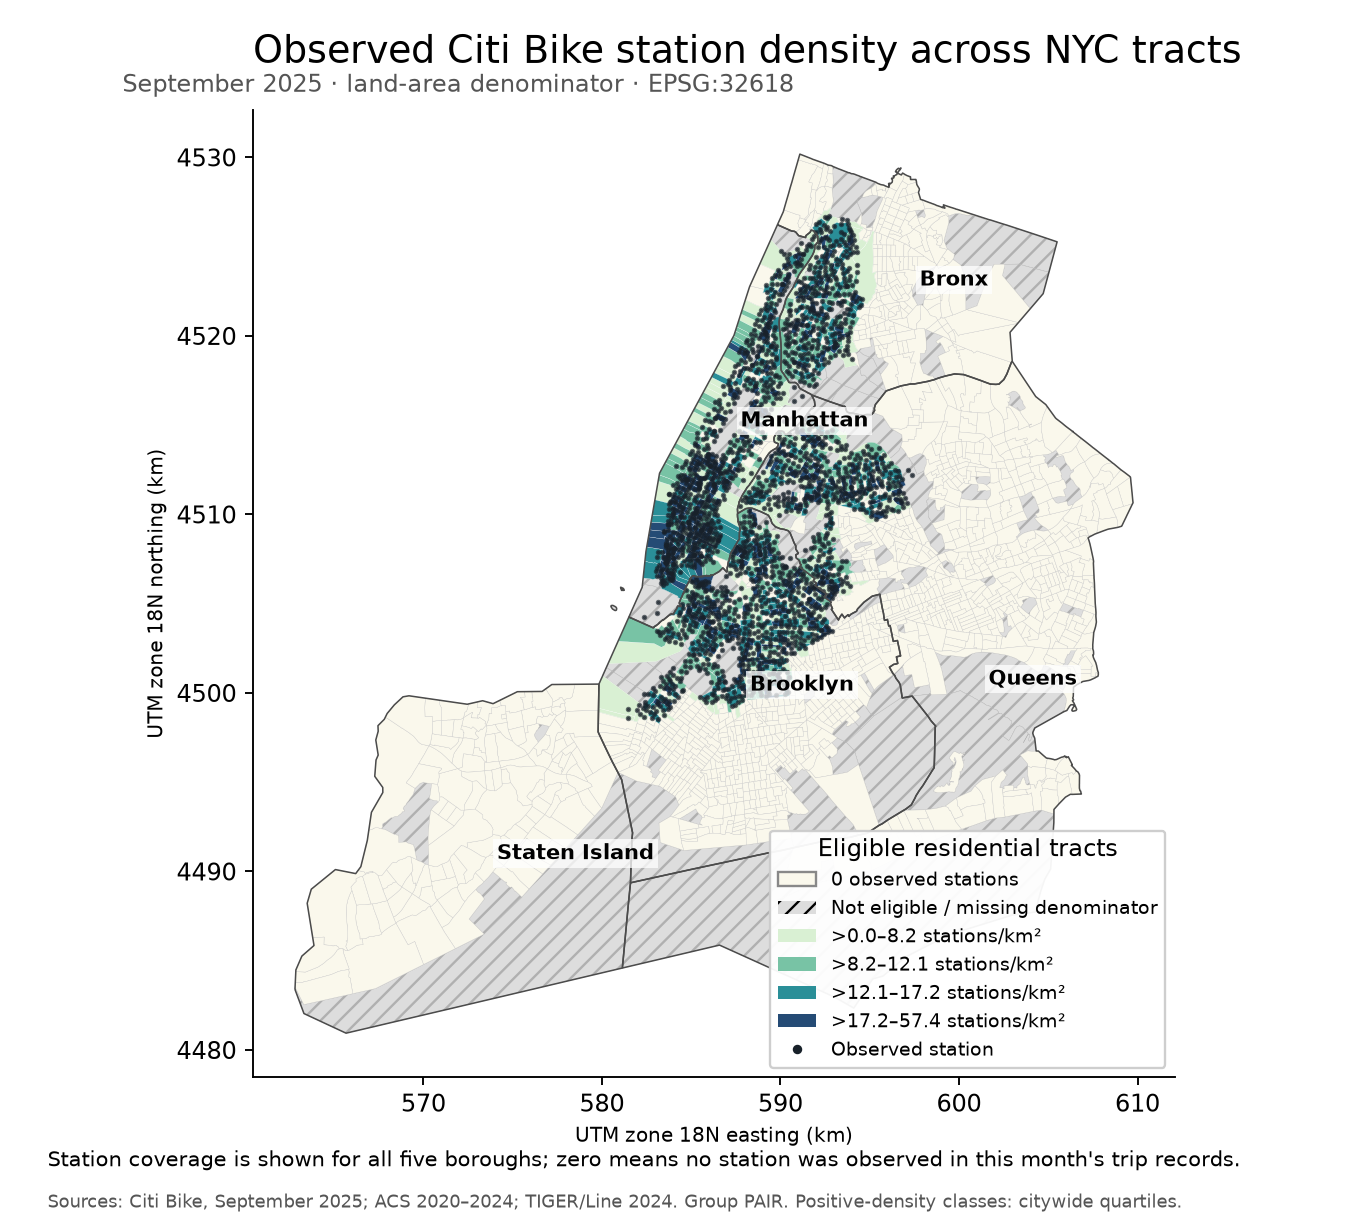

Station coverage is shown for all five boroughs; zero means no station was observed in this month's trip records.

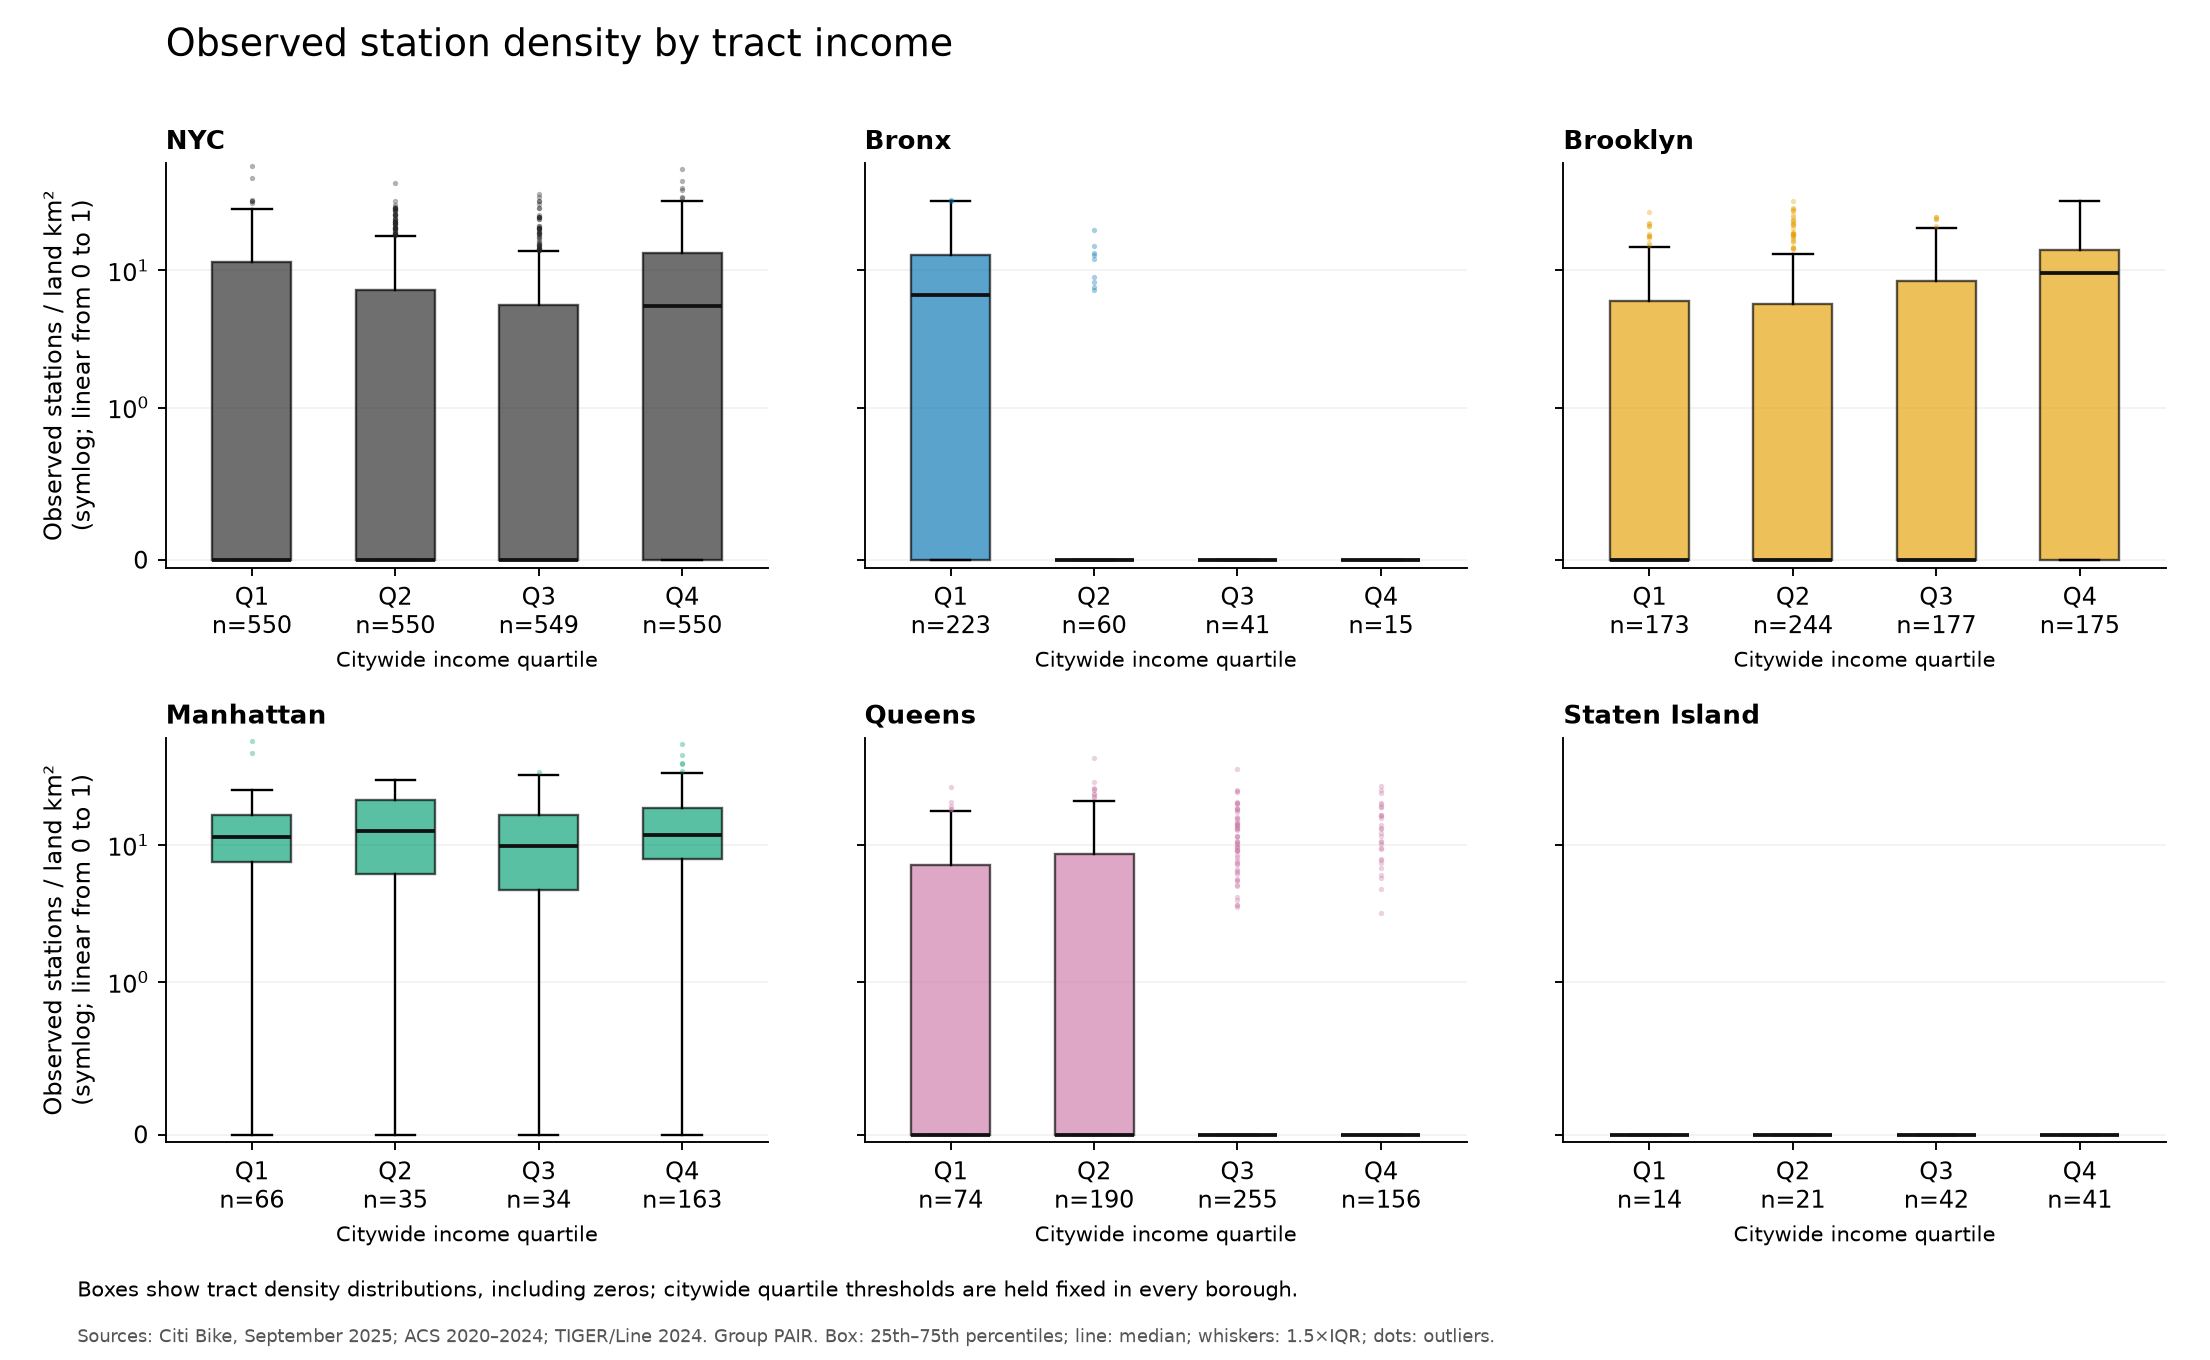

Boxes show tract density distributions, including zeros; citywide quartile thresholds are held fixed in every borough.

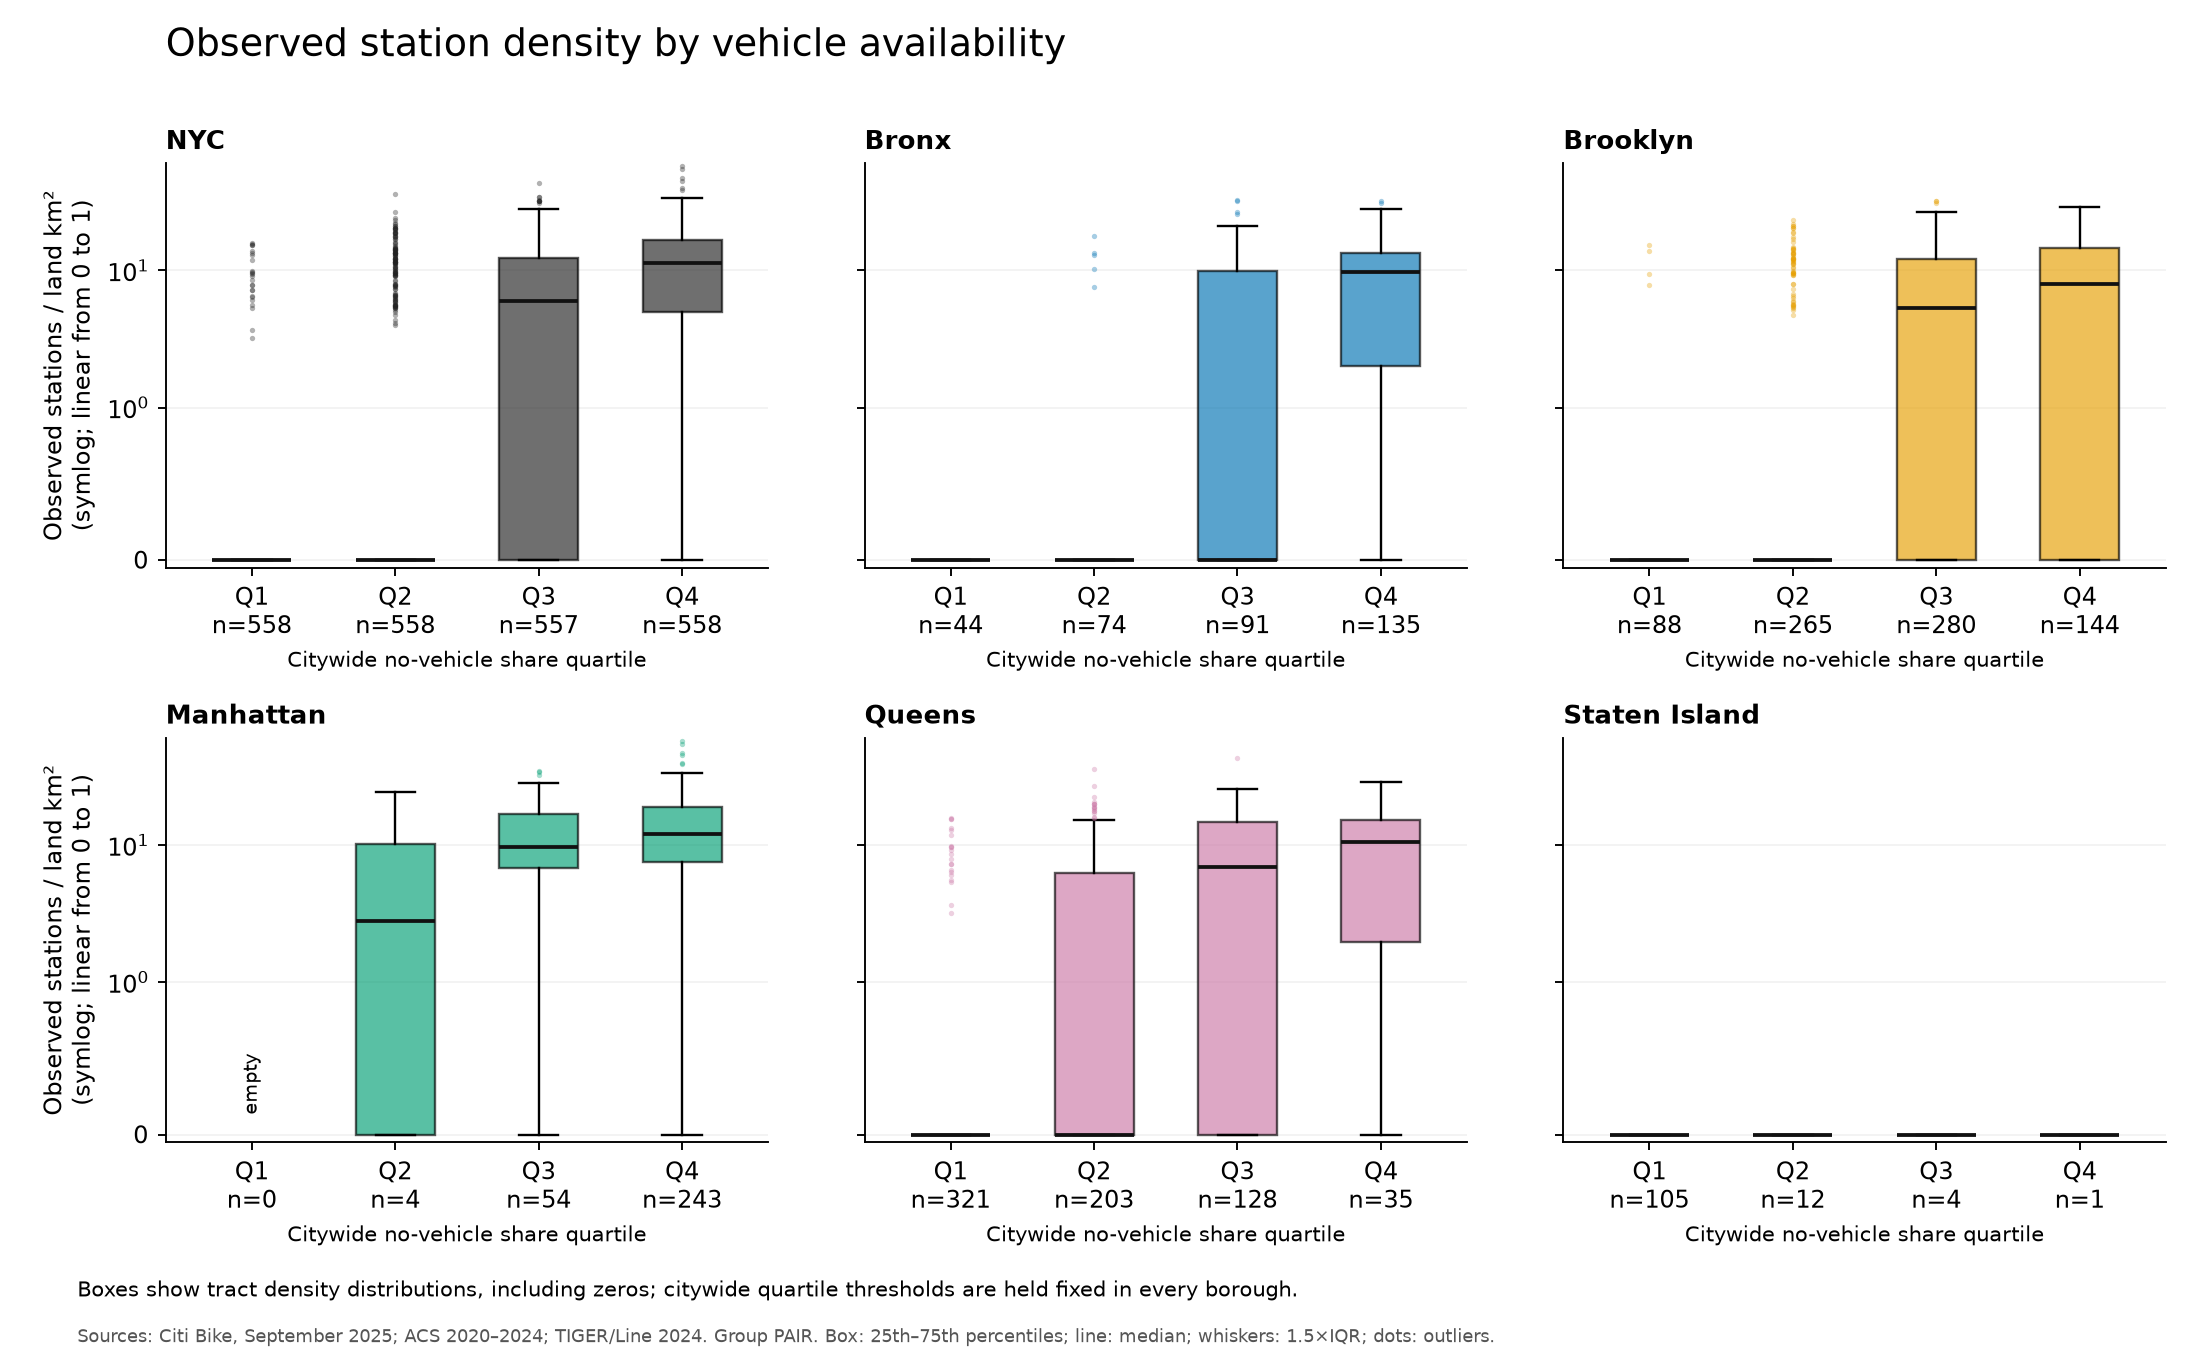

Boxes show tract density distributions, including zeros; citywide quartile thresholds are held fixed in every borough.

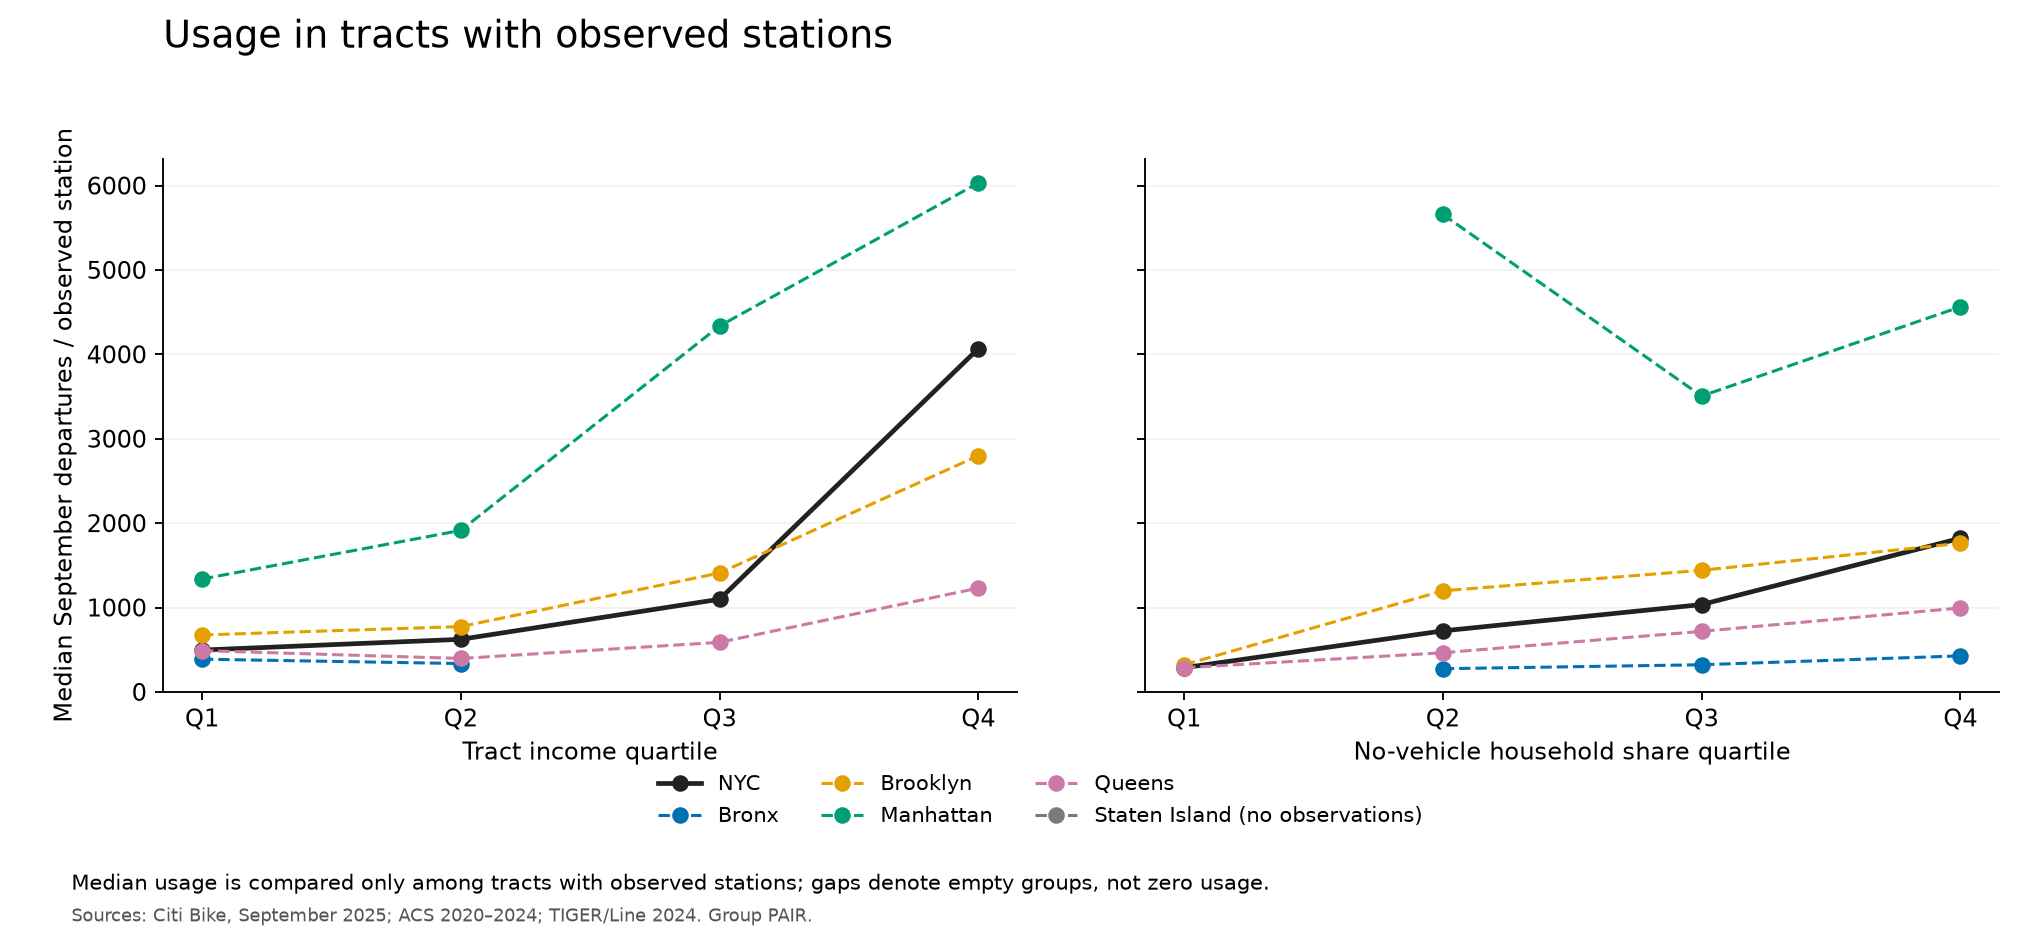

Median usage is compared only among tracts with observed stations; gaps denote empty groups, not zero usage.

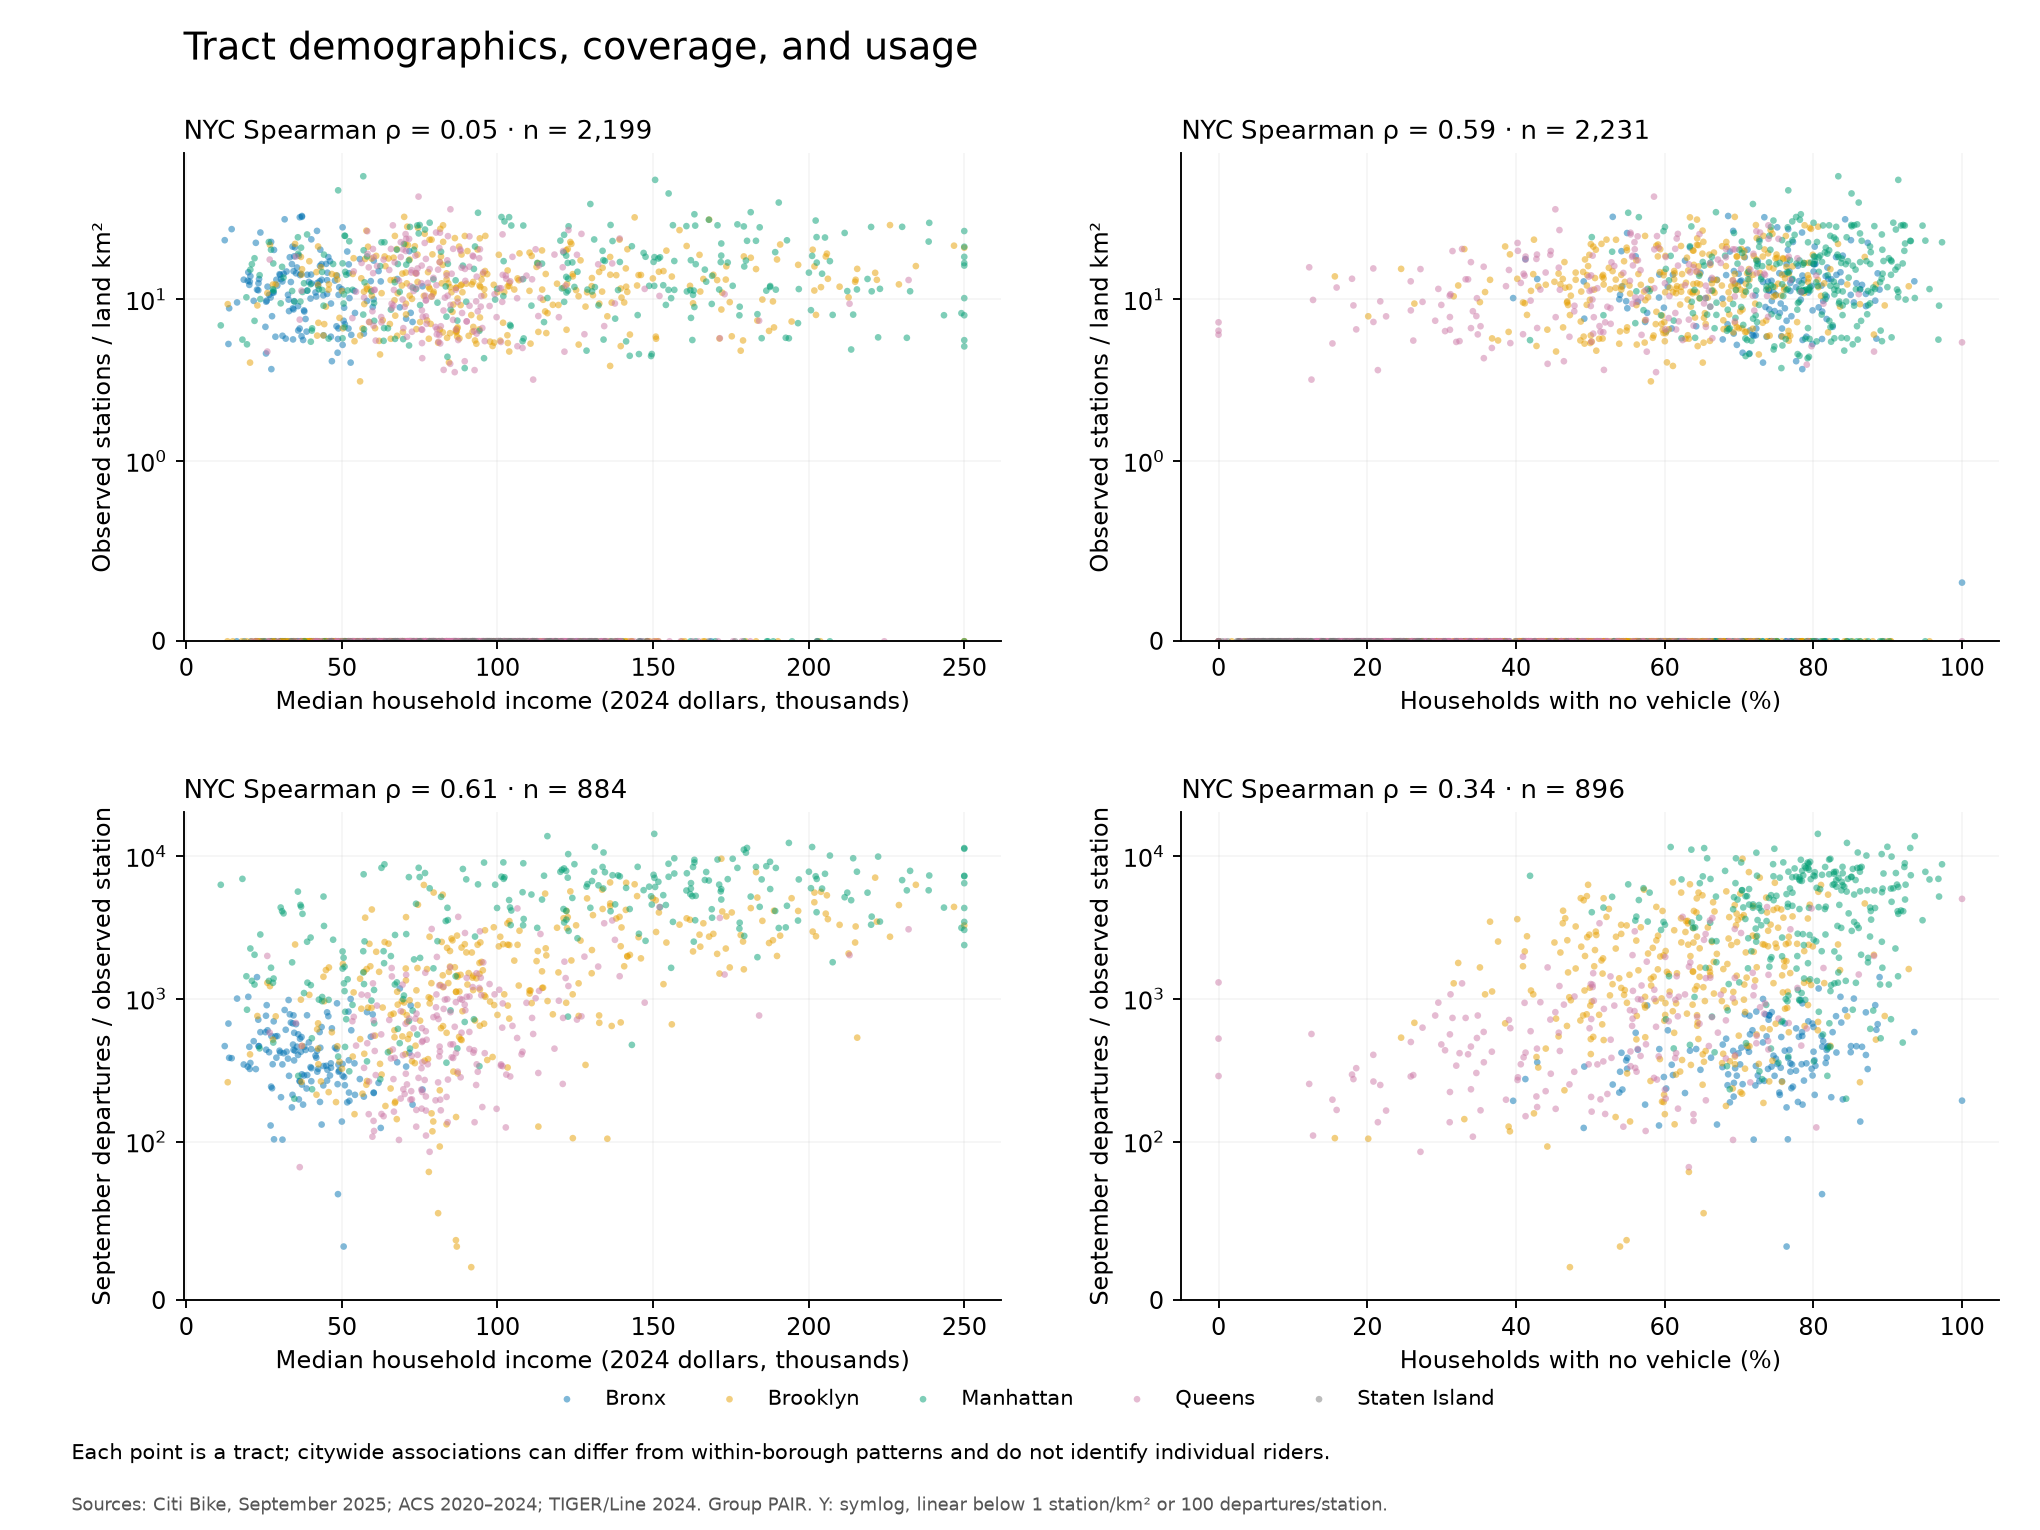

Each point is a tract; citywide associations can differ from within-borough patterns and do not identify individual riders.

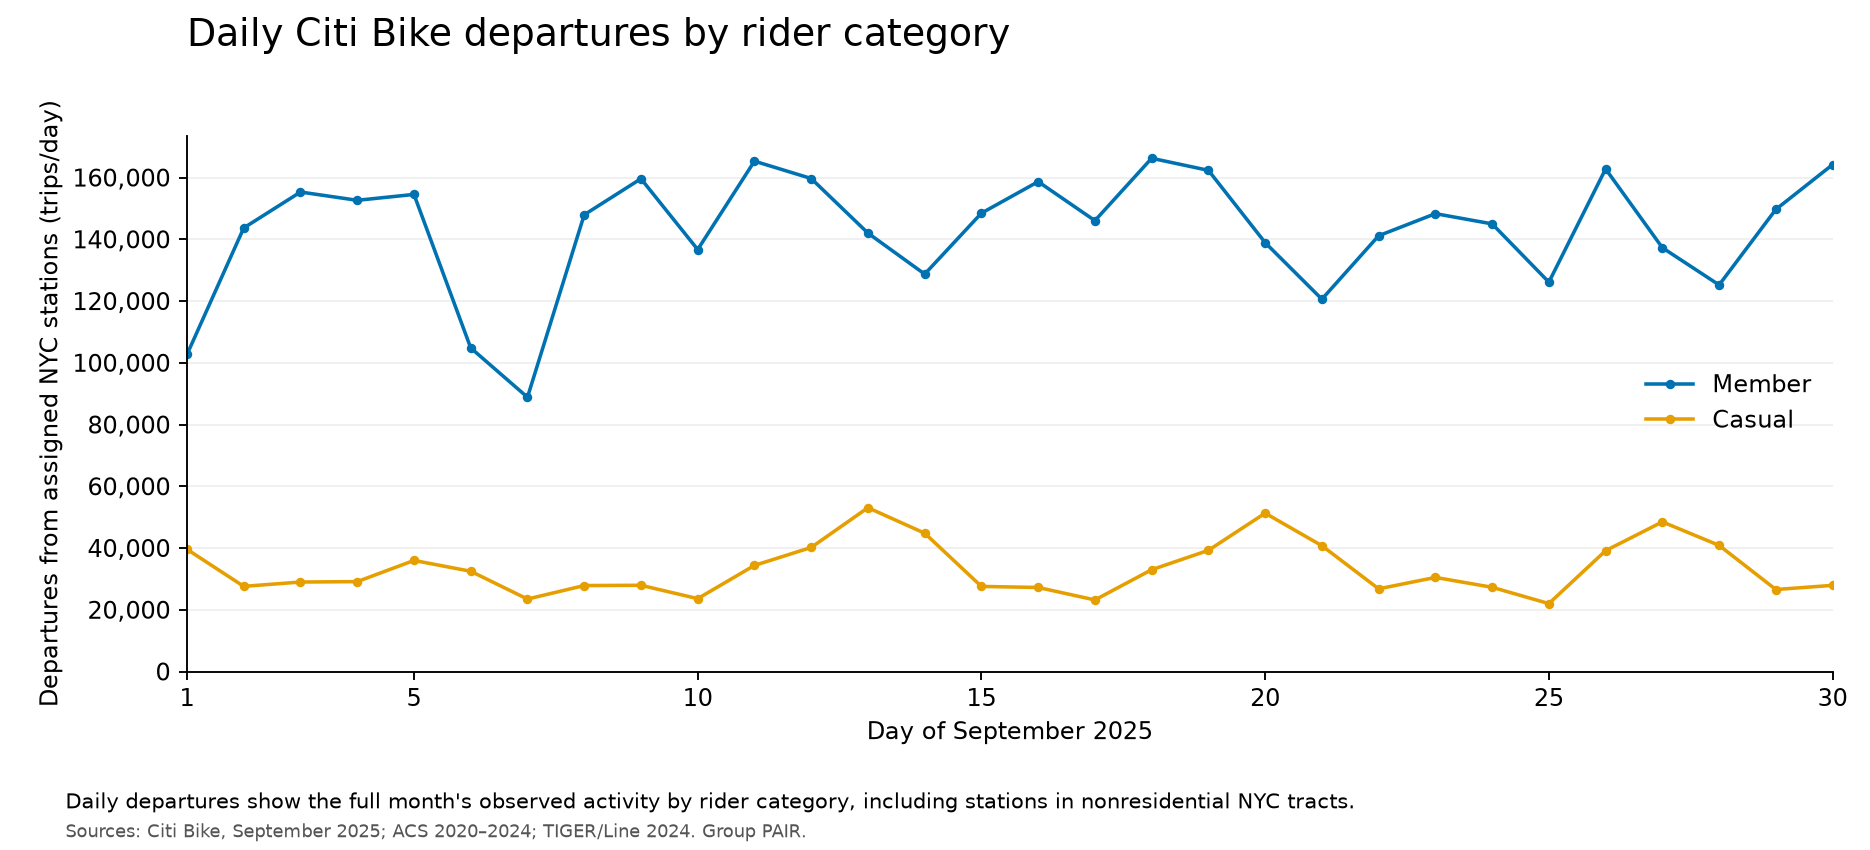

Daily departures show the full month's observed activity by rider category, including stations in nonresidential NYC tracts.

In [6]:
figures = json.loads(Path('visualizations/captions.json').read_text())['figures']
for figure in figures:
    display(Image(filename=str(Path('visualizations') / figure['file']), width=1000))
    display(Markdown(figure['caption']))

## Early interpretation and remaining work
The report narrative below is generated from the same summary tables as the figures. It describes observed coverage and activity, not dock capacity, reliable availability, rider residence, or causal effects. A tract can have no observed station yet be close to a station across its boundary.

In [7]:
display(Markdown(Path('docs/early_results.md').read_text()))
display(pd.Series(validation['checks'], name='passed'))

# Early results

Observed coverage is uneven: 1,335 of 2,231 eligible tracts (59.8%) have no observed station. The share is 11.6% in Manhattan, 72.9% in Queens, and 100% in Staten Island. These are observations from trip records, not a claim that residents cannot reach stations in adjacent tracts.

The citywide income–density correlation is nearly flat (ρ=0.05), but borough patterns differ: Bronx -0.53, Brooklyn 0.30, Manhattan 0.05, and Queens -0.13. No-vehicle household share is more positively associated with density citywide (ρ=0.59). Its highest quartile has 21.9% zero-station tracts, versus 95.5% in its lowest quartile. The borough differences caution against a single citywide income story.

Among tracts with stations, median September departures per observed station rise from 496 in the lowest income quartile to 4,068 in the highest. This conditional comparison describes activity where stations were observed, not demand in unserved tracts or trips made by residents. Daily variation is visible below; weather, weekends, and holidays have not been modeled.

ACS estimates cover five years and have sampling uncertainty; they do not describe individual riders. Tract boundaries, jobs, transit, land use, and partial-month operation can affect the patterns. The one flagged station location spans 291 m; its modal pair accounts for 383 of 389 endpoint observations, and both locations fall in the same tract. We retain the modal location with no manual override. Low observed density is not a direct walking-access measure, and low usage does not establish low or unmet demand.

All 15 numerical/spatial reconciliation checks passed. NYC station departures total 5,284,398; 196,150 occur in tracts excluded from residential comparisons and remain included in daily activity.


six_files_processed                  True
sequential_exclusions_reconcile      True
retained_start_ids_reconcile         True
retained_missingness_reconciles      True
one_station_row_per_id               True
one_row_per_tract                    True
all_geoid_lengths                    True
station_tract_totals_reconcile       True
nyc_departures_reconcile             True
nyc_borough_departures_reconcile     True
nyc_daily_departures_reconcile       True
zero_station_usage_is_missing        True
zero_station_departures_are_zero     True
household_numerators_valid           True
positive_residential_denominators    True
Name: passed, dtype: bool

## Plan to finish
- **Ethan, November 16:** review coordinate flags and tract-boundary sensitivity; compare land/population normalization and usage among stations observed in both first and last weeks.
- **Tim, December 6:** build the two interactive maps, daily animation, borough filters, and GitHub Pages draft with fixed scales.
- **Both, December 15:** review interpretations, rerun all code, and finalize.

Feedback requested: How should near-boundary stations be represented without overstating walking access? Are these descriptive tract comparisons sufficient given ACS uncertainty and correlated land use? Is first/last-week presence a useful sensitivity check for partial-month exposure?